In [1]:
import json
with open('correct_product_features.json', 'r') as f:
    data = json.load(f)

    unverified_features_count = 0
    values_count = 0
    total_entries = len(data)

for entry in data.values():
    if entry['unverified_features']:
        unverified_features_count += 1
    if entry['values']:
        values_count += 1

print(f"Unverified features count: {unverified_features_count}")
print(f"Values count: {values_count}")
print(f"Total entries: {total_entries}")

Unverified features count: 90
Values count: 45
Total entries: 135


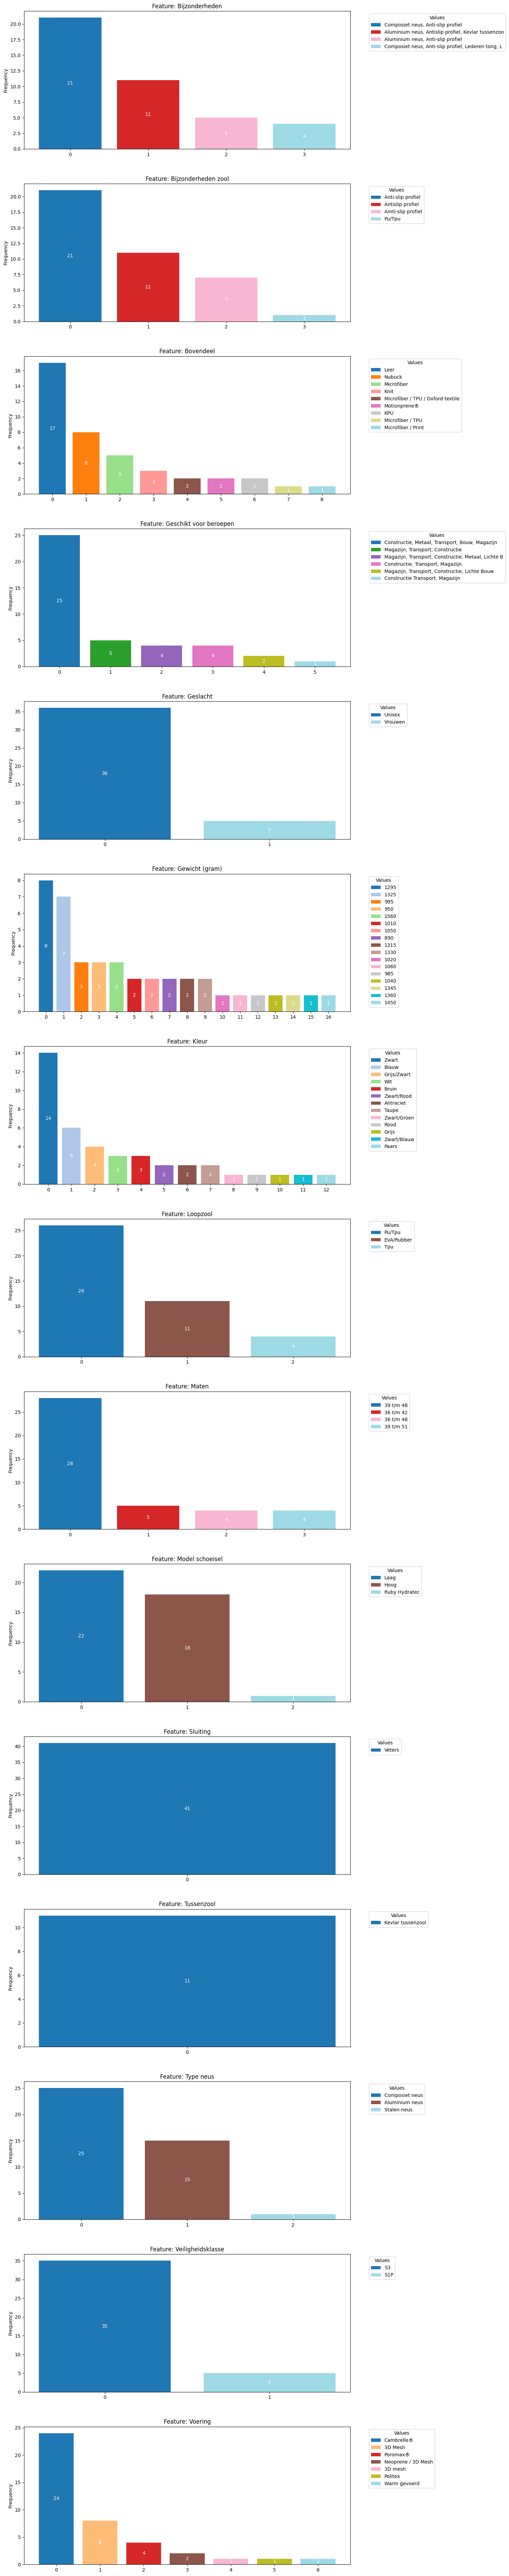

In [15]:
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np

# Load the JSON data
with open('correct_product_features.json', 'r') as file:
    data = json.load(file)

# Initialize a dictionary to store the frequency of unique values for each feature
feature_counts = defaultdict(lambda: defaultdict(int))

# Iterate through the products and extract the features
for product_id, product_info in data.items():
    verified_features = product_info.get('values', {})
    for feature, value in verified_features.items():
        if value is not None:
            feature_counts[feature][value] += 1

feature_counts.pop('Naam (omschrijving)')

# Determine the number of rows and columns for the grid
num_features = len(feature_counts)
num_cols = 1
num_rows = (num_features + num_cols - 1)

# Create a grid of subplots
fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, num_rows * 5))
axes = axes.flatten()

# Define a colormap
cmap = plt.get_cmap("tab20")

# Plot the data
for idx, (feature, values) in enumerate(feature_counts.items()):
    ax = axes[idx]
    sorted_values = dict(sorted(values.items(), key=lambda item: item[1], reverse=True))
    x = np.arange(len(sorted_values))  # Create numeric x-coordinates
    bars = ax.bar(x, sorted_values.values(), color=cmap(np.linspace(0, 1, len(sorted_values))))
    # Cap the length of legend labels to 20 characters
    legend_labels = [label[:50] for label in sorted_values.keys()]
    ax.legend(bars, legend_labels, title="Values", bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.set_ylabel('Frequency')
    ax.set_title(f'Feature: {feature}')
    ax.set_xticks(x)  # Set the tick positions
    # ax.set_xticklabels(list(sorted_values.keys()), rotation=90)
    
    # Add labels inside the bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, height / 2, f'{height}', ha='center', va='center', color='white')

# Remove any empty subplots
for idx in range(num_features, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()